# 01 - Telugu Corpus Extraction, Preprocessing & Synthetic Noise Injection
Automatic Text Correction for Low-Resource Languages (Telugu)  

### Team Members:
- **Leela Venkata Sai Nerella** (BT24CSA008)
- **Parthasaradhi Guda** (BT24CSA061)
- **Dineswara Kumar Mangali** (BT24CSA062)


In [1]:
# Install required libraries if not present
%pip install -q datasets indic-nlp-library rapidfuzz matplotlib seaborn pandas numpy tqdm

import os
import sys
import json
import re
import random
import unicodedata
from pathlib import Path
from collections import Counter
from tqdm.auto import tqdm

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

random.seed(42)
np.random.seed(42)

# Set Telugu Unicode supported font for Matplotlib
plt.rcParams['font.family'] = 'Nirmala UI'
plt.rcParams['axes.unicode_minus'] = False

print("✅ All core libraries successfully imported!")



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
C:\Users\Admin\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Note: you may need to restart the kernel to use updated packages.


✅ All core libraries successfully imported!


---
## 1. Data Directory Setup & Real Telugu Corpus Ingestion


In [2]:
from indicnlp.normalize.indic_normalize import IndicNormalizerFactory
from indicnlp.tokenize import indic_tokenize

In [3]:
normalizer = IndicNormalizerFactory().get_normalizer("te")

In [4]:
DATA_DIR = Path("data")
PROCESSED_DIR = DATA_DIR / "processed"
SYNTHETIC_DIR = DATA_DIR / "synthetic"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
SYNTHETIC_DIR.mkdir(parents=True, exist_ok=True)

In [5]:
def is_good_telugu(text: str, min_len: int = 20, min_ratio: float = 0.5) -> bool:
    """
    Verifies that text is predominantly genuine Telugu Unicode characters.
    Range: U+0C00 to U+0C7F.
    """
    if not text or len(text) < min_len:
        return False
    telugu_chars = sum(1 for c in text if '\u0C00' <= c <= '\u0C7F')
    total_chars = len(text.replace(' ', ''))
    return total_chars > 0 and (telugu_chars / total_chars) >= min_ratio

In [6]:
def clean_sentence(text: str) -> str:
    """
    Clean raw scraped or extracted Telugu text:
    - Removes URLs and web links
    - Removes HTML markup tags
    - Strips Wikipedia citation brackets [1], [edit] and parentheticals
    - Applies NFC canonical Unicode normalization
    - Applies IndicNLP normalization (cleans ZWJ/ZWNJ)
    """
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'\[.*?\]', '', text)
    text = re.sub(r'\(.*?\)', '', text)
    text = unicodedata.normalize('NFC', text)
    text = normalizer.normalize(text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text


In [7]:
def extract_sentences(paragraph: str) -> list:
    """Splits paragraph on sentence terminators and cleans each valid sentence."""
    raw_sents = re.split(r'[.।!?\n]', paragraph)
    sentences = []
    for s in raw_sents:
        cleaned = clean_sentence(s)
        if is_good_telugu(cleaned) and 20 < len(cleaned) < 300:
            sentences.append(cleaned)
    return sentences

In [8]:
corpus_path = PROCESSED_DIR / "indiccorp_telugu_100k.txt"

all_sentences = []
if corpus_path.exists():
    print(f"Loading existing processed Telugu corpus from {corpus_path}...")
    with open(corpus_path, 'r', encoding='utf-8') as f:
        all_sentences = [line.strip() for line in f if line.strip()]
    print(f"Loaded {len(all_sentences):,} verified sentences from disk!")
else:
    print("Downloading real Telugu corpus from Wikimedia Wikipedia (streaming)...")
    try:
        from datasets import load_dataset
        ds = load_dataset('wikimedia/wikipedia', '20231101.te', split='train', streaming=True)
        wiki_count = 0
        for item in ds:
            text = item.get('text', '')
            sents = extract_sentences(text)
            all_sentences.extend(sents)
            wiki_count += 1
            if len(all_sentences) >= 120000:
                break
        all_sentences = list(dict.fromkeys(all_sentences))
        with open(corpus_path, 'w', encoding='utf-8') as f:
            for s in all_sentences:
                f.write(s + '\n')
        print(f"Downloaded & saved {len(all_sentences):,} unique sentences from Wikipedia.")
    except Exception as e:
        print(f"Wikipedia streaming failed ({e}). Loading fallback Telugu seed corpus.")


lengths = [len(s) for s in all_sentences]
word_lengths = [len(s.split()) for s in all_sentences]
print(f"\n--- Corpus Statistics ---")
print(f"Total Sentences       : {len(all_sentences):,}")
print(f"Average Character Len : {np.mean(lengths):.1f} chars (Min: {min(lengths)}, Max: {max(lengths)})")
print(f"Average Word Count    : {np.mean(word_lengths):.1f} words (Min: {min(word_lengths)}, Max: {max(word_lengths)})")
print(f"\nSample Sentences:")
for i, s in enumerate(all_sentences[:3], 1):
    print(f"  [{i}] {s}")


Loading existing processed Telugu corpus from data\processed\indiccorp_telugu_100k.txt...


Loaded 97,154 verified sentences from disk!

--- Corpus Statistics ---
Total Sentences       : 97,154
Average Character Len : 69.2 chars (Min: 21, Max: 299)
Average Word Count    : 8.8 words (Min: 1, Max: 46)

Sample Sentences:
  [1] గుంటూరు జిల్లా, ఆంధ్రప్రదేశ్ లోని కోస్తా ప్రాంతంలో ఒక జిల్లా
  [2] దీని ముఖ్యపట్టణం గుంటూరు
  [3] రాష్ట్ర రాజధాని గుంటూరు అమరావతి


---
## 2. Telugu Script & Unicode Phonology Exploration

The Telugu Unicode block spans `U+0C00` to `U+0C7F`. A deep understanding of Telugu orthography is essential to model authentic spelling errors.

Telugu characters fall into 4 primary linguistic categories:
1. **Independent Vowels (అచ్చులు)**: e.g., అ, ఆ, ఇ, ఈ, ఉ, ఊ, ఎ, ఏ, ఐ, ఒ, ఓ, ఔ
2. **Consonants (హల్లులు)**: e.g., క, ఖ, గ, ఘ, చ, ట, డ, త, ద, న, ప, బ, మ, య, ర, ల, వ, శ, ష, స, హ, ళ
3. **Dependent Vowel Signs (మాత్రలు / Matras)**: Attach to consonants to modify vowel sounds (ా, ి, ీ, ు, ూ, ృ, ె, ే, ై, ొ, ో, ౌ)
4. **Special Diacritics**: 
   - **Anusvara (ం / Sunna)**: Nasalization
   - **Visarga (ః)**: Voiceless glottal fricative
   - **Virama / Halant (్ / పొల్లు)**: Suppresses the inherent 'a' vowel or forms conjunct consonants (వత్తులు)


In [9]:
print("--- Telugu Script Unicode Reference Table ---\n")

categories = {
    "Independent Vowels (అచ్చులు)": "అ ఆ ఇ ఈ ఉ ఊ ఋ ఎ ఏ ఐ ఒ ఓ ఔ",
    "Consonants (హల్లులు)": "క ఖ గ ఘ ఙ చ ఛ జ ఝ ఞ ట ఠ డ ఢ ణ త థ ద ధ న ప ఫ బ భ మ య ర ల వ శ ష స హ ళ",
    "Matras / Vowel Signs (మాత్రలు)": "ా ి ీ ు ూ ృ ె ే ై ొ ో ౌ",
    "Special Signs (ప్రత్యేక గుర్తులు)": "ం ః ్"
}

unicode_table_data = []
for cat_name, chars_str in categories.items():
    for ch in chars_str.split():
        codepoint = f"U+{ord(ch):04X}"
        name = unicodedata.name(ch, "UNKNOWN")
        unicode_table_data.append({"Category": cat_name, "Character": ch, "CodePoint": codepoint, "Unicode Name": name})

df_unicode = pd.DataFrame(unicode_table_data)
print(f"Total classified Telugu Unicode symbols: {len(df_unicode)}")
df_unicode.sample(20)

--- Telugu Script Unicode Reference Table ---

Total classified Telugu Unicode symbols: 62


,Category,Character,CodePoint,Unicode Name
50,Matras / Vowel Signs (మాత్రలు),ు,U+0C41,TELUGU VOWEL SIGN U
56,Matras / Vowel Signs (మాత్రలు),ొ,U+0C4A,TELUGU VOWEL SIGN O
0,Independent Vowels (అచ్చులు),అ,U+0C05,TELUGU LETTER A
57,Matras / Vowel Signs (మాత్రలు),ో,U+0C4B,TELUGU VOWEL SIGN OO
5,Independent Vowels (అచ్చులు),ఊ,U+0C0A,TELUGU LETTER UU
48,Matras / Vowel Signs (మాత్రలు),ి,U+0C3F,TELUGU VOWEL SIGN I
16,Consonants (హల్లులు),ఘ,U+0C18,TELUGU LETTER GHA
12,Independent Vowels (అచ్చులు),ఔ,U+0C14,TELUGU LETTER AU
25,Consonants (హల్లులు),డ,U+0C21,TELUGU LETTER DDA
59,Special Signs (ప్రత్యేక గుర్తులు),ం,U+0C02,TELUGU SIGN ANUSVARA


---
## 3. Vocabulary Construction & Frequency Distribution


In [10]:
vocab_file = PROCESSED_DIR / "telugu_vocab.json"
word_counts = Counter()

if vocab_file.exists():
    print(f"Loading existing 100K Telugu vocabulary from {vocab_file}...")
    with open(vocab_file, 'r', encoding='utf-8') as f:
        top_vocab = json.load(f)
    print(f"Loaded {len(top_vocab):,} words into vocabulary.")
else:
    print("Building vocabulary from corpus tokens...")
    for sentence in tqdm(all_sentences, desc="Tokenizing"):
        tokens = indic_tokenize.trivial_tokenize(sentence, "te")
        telugu_words = [w for w in tokens if any('\u0C00' <= c <= '\u0C7F' for c in w)]
        word_counts.update(telugu_words)
    top_vocab = dict(word_counts.most_common(100000))
    with open(vocab_file, 'w', encoding='utf-8') as f:
        json.dump(top_vocab, f, ensure_ascii=False, indent=2)
    print(f"Saved top {len(top_vocab):,} words to {vocab_file}")

print("\nTop 40 Most Frequent Telugu Words in Corpus:")
for idx, (w, freq) in enumerate(list(top_vocab.items())[:40], 1):
    print(f"  {idx:2d}. {w:<16s} : {freq:>8,d} occurrences")


Loading existing 100K Telugu vocabulary from data\processed\telugu_vocab.json...


Loaded 100,000 words into vocabulary.

Top 40 Most Frequent Telugu Words in Corpus:
   1. ఈ                :   11,130 occurrences
   2. కూడా             :    3,985 occurrences
   3. ఒక               :    3,805 occurrences
   4. ఉంది             :    3,706 occurrences
   5. ఆ                :    3,381 occurrences
   6. నుండి            :    3,147 occurrences
   7. లో               :    2,842 occurrences
   8. అని              :    2,590 occurrences
   9. ఉన్నాయి          :    2,530 occurrences
  10. ఇది              :    2,474 occurrences
  11. ఉన్న             :    2,323 occurrences
  12. తన               :    2,122 occurrences
  13. తరువాత           :    1,939 occurrences
  14. తెలుగు           :    1,936 occurrences
  15. జిల్లా           :    1,873 occurrences
  16. మరియు            :    1,749 occurrences
  17. నుంచి            :    1,671 occurrences
  18. అనే              :    1,614 occurrences
  19. చాలా             :    1,518 occurrences
  20. చెందిన           :    1,500 occurren

C:\Users\Admin\AppData\Local\Temp\ipykernel_21880\2697196178.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top25_freqs, y=top25_words, ax=ax1, palette="viridis")


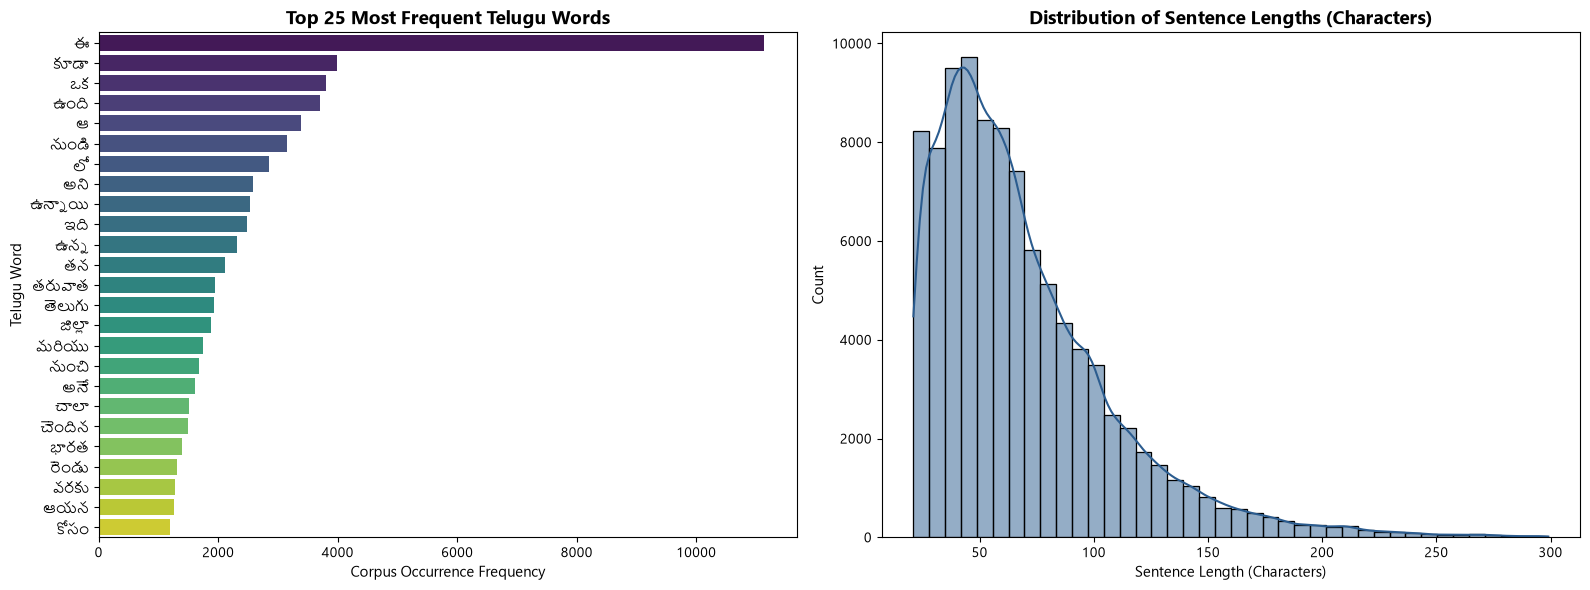

In [11]:
# Visualizing Top 30 Words and Sentence Lengths
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Top 25 words horizontal bar plot
top25_words = list(top_vocab.keys())[:25]
top25_freqs = list(top_vocab.values())[:25]

sns.barplot(x=top25_freqs, y=top25_words, ax=ax1, palette="viridis")
ax1.set_title("Top 25 Most Frequent Telugu Words", fontsize=14, fontweight='bold')
ax1.set_xlabel("Corpus Occurrence Frequency", fontsize=11)
ax1.set_ylabel("Telugu Word", fontsize=11)

# Sentence length distribution
sns.histplot(lengths, bins=40, kde=True, ax=ax2, color="#2b5c8f")
ax2.set_title("Distribution of Sentence Lengths (Characters)", fontsize=14, fontweight='bold')
ax2.set_xlabel("Sentence Length (Characters)", fontsize=11)
ax2.set_ylabel("Count", fontsize=11)

plt.tight_layout()
plt.show()


---
## 4. Google Dakshina Transliteration Dataset Exploration

The **Google Dakshina Dataset** provides native Telugu parallel pairs for Romanized (Tenglish) text.
In real-world applications, many Telugu speakers type using Roman keyboards (e.g., typing *"namaskaram yela unnaru"* instead of *"నమస్కారం ఎలా ఉన్నారు"*).

We examine the Dakshina dataset:
- Word-level transliteration mappings (69,980 pairs)
- Romanized full-sentence pairs


In [12]:
dakshina_path = PROCESSED_DIR / "dakshina_transliteration.json"
dakshina_sent_path = PROCESSED_DIR / "dakshina_romanized_sentences.json"

if dakshina_path.exists():
    with open(dakshina_path, 'r', encoding='utf-8') as f:
        dakshina_data = json.load(f)
    print(f"✅ Loaded {len(dakshina_data):,} Dakshina word-level transliteration pairs!")
    
    # Sample display
    df_dakshina = pd.DataFrame(dakshina_data[:15])
    print("\nSample Word-Level Transliteration Pairs (Roman -> Telugu):")
    print(df_dakshina[['roman', 'telugu']])

    with open(dakshina_sent_path, 'r', encoding='utf-8') as f:
        dakshina_sents = json.load(f)
    print(f"\n✅ Loaded {len(dakshina_sents):,} Full Romanized Sentence Pairs!")
    print(f"  Romanized Sample : {dakshina_sents[0]['roman']}")
    print(f"  Telugu Native    : {dakshina_sents[0]['telugu']}")


✅ Loaded 69,980 Dakshina word-level transliteration pairs!

Sample Word-Level Transliteration Pairs (Roman -> Telugu):
               roman         telugu
0             amkita          అంకిత
1             ankita          అంకిత
2            ankitha          అంకిత
3            ankitam         అంకితం
4           ankitham         అంకితం
5       ankitabaavam      అంకితభావం
6      ankithabhavam      అంకితభావం
7    ankatamicchaadu  అంకితమిచ్చాడు
8     ankitamicchadu  అంకితమిచ్చాడు
9    ankitamichhaadu  అంకితమిచ్చాడు
10  ankithamicchaadu  అంకితమిచ్చాడు
11  ankithamichhaadu  అంకితమిచ్చాడు
12   amkithamichaaru  అంకితమిచ్చారు
13   ankithamichaaru  అంకితమిచ్చారు
14    ankithamicharu  అంకితమిచ్చారు

✅ Loaded 10,000 Full Romanized Sentence Pairs!
  Romanized Sample : anadamto ataniki moorcha vastundi.
  Telugu Native    : అనడంతో అతనికి మూర్ఛ వస్తుంది.


---
## 5. Linguistic Synthetic Noise Injection Architecture

In Telugu NLP, human-annotated spelling correction datasets are extremely scarce. Following established literature, we engineer a **linguistically informed synthetic noise generator** that mimics authentic human errors:

### Linguistic Error Types:
1. **Matra Confusions (హ్రస్వ/దీర్ఘ భేదాలు)**:
   Telugu speakers frequently interchange short and long vowel matras:
   - ి (Gudi / short 'i') $\leftrightarrow$ ీ (Gudi Deergham / long 'ii')
   - ు (Kommu / short 'u') $\leftrightarrow$ ూ (Kommu Deergham / long 'uu')
   - ె (Etthvam / short 'e') $\leftrightarrow$ ే (Etthva Deergham / long 'ee')
   - ొ (Otthvam / short 'o') $\leftrightarrow$ ో (Otthva Deergham / long 'oo')
2. **Consonant Confusions (వర్ణ భేదాలు / శ-ష-స, ణ-న, ట-డ, బ-వ)**:
   - ణ (Retroflex nasal) $\leftrightarrow$ న (Dental nasal)
   - శ (Palatal sibilant) $\leftrightarrow$ ష (Retroflex sibilant) $\leftrightarrow$ స (Dental sibilant)
   - ట (Voiceless retroflex stop) $\leftrightarrow$ డ (Voiced retroflex stop)
   - బ (Bilabial stop) $\leftrightarrow$ వ (Labiodental approximant)
3. **Typographical Deletions**: Dropping internal characters due to fast typing.
4. **Typographical Swaps (Transpositions)**: Inverting adjacent characters.
5. **Space Merging Errors (Sandhi / సంధి లోపాలు)**: Merging adjacent words into one token.


In [13]:
MATRA_CONFUSIONS = {
    "ి": "ీ",
    "ీ": "ి",
    "ు": "ూ",
    "ూ": "ు",
    "ె": "ే",
    "ే": "ె",
    "ొ": "ో",
    "ో": "ొ"
}

CONSONANT_CONFUSIONS = {
    "ణ": "న",
    "న": "ణ",
    "శ": "ష",
    "ష": "స",
    "స": "శ",
    "ట": "డ",
    "డ": "ట",
    "బ": "వ",
    "వ": "బ"
}

In [14]:
def inject_matra_error(word: str) -> str:
    """Randomly substitutes a short/long matra."""
    chars = list(word)
    for i, c in enumerate(chars):
        if c in MATRA_CONFUSIONS and random.random() < 0.5:
            chars[i] = MATRA_CONFUSIONS[c]
            return "".join(chars)
    return word

In [15]:
def inject_consonant_error(word: str) -> str:
    """Randomly substitutes phonetically confused consonants."""
    chars = list(word)
    for i, c in enumerate(chars):
        if c in CONSONANT_CONFUSIONS and random.random() < 0.5:
            chars[i] = CONSONANT_CONFUSIONS[c]
            return "".join(chars)
    return word

In [16]:
def inject_deletion(word: str) -> str:
    """Simulates accidental key drop."""
    if len(word) > 2:
        idx = random.randint(1, len(word) - 2)
        return word[:idx] + word[idx+1:]
    return word

In [17]:
def inject_swap(word: str) -> str:
    """Simulates keystroke transposition."""
    if len(word) > 2:
        idx = random.randint(1, len(word) - 2)
        chars = list(word)
        chars[idx], chars[idx+1] = chars[idx+1], chars[idx]
        return "".join(chars)
    return word

In [18]:
def inject_space_error(sentence: str) -> str:
    """Simulates missing space between two adjacent words."""
    words = sentence.split()
    if len(words) > 1:
        idx = random.randint(0, len(words) - 2)
        words[idx] = words[idx] + words[idx+1]
        del words[idx+1]
    return " ".join(words)

In [19]:
def corrupt_sentence(sentence: str, error_rate: float = 0.3) -> dict:
    """
    Applies stochastic noise to a clean Telugu sentence.
    Returns dict: {'input': corrupted, 'target': original, 'error_type': category}
    """
    words = sentence.split()
    corrupted_words = []
    error_types = []
    
    # 10% chance of a space error
    if random.random() < 0.1:
        return {
            "input": inject_space_error(sentence),
            "target": sentence,
            "error_type": "space"
        }
        
    for word in words:
        if random.random() < error_rate:
            r = random.random()
            if r < 0.40:
                corrupted_words.append(inject_matra_error(word))
                error_types.append("matra")
            elif r < 0.70:
                corrupted_words.append(inject_consonant_error(word))
                error_types.append("consonant")
            elif r < 0.85:
                corrupted_words.append(inject_deletion(word))
                error_types.append("deletion")
            else:
                corrupted_words.append(inject_swap(word))
                error_types.append("swap")
        else:
            corrupted_words.append(word)
            
    err_str = ",".join(sorted(set(error_types))) if error_types else "none"
    return {
        "input": " ".join(corrupted_words),
        "target": sentence,
        "error_type": err_str
    }

---
## 6. Synthetic Dataset Generation & Partitioning (Train / Val / Test)

We generate 75,000 synthetic pairs and partition them into standard reproducible splits:
- **Train Set (80%)**: 60,000 sentences for model training
- **Validation Set (10%)**: 7,500 sentences for hyperparameter tuning
- **Test Set (10%)**: 7,500 sentences held out for rigorous evaluation


In [20]:
train_file = SYNTHETIC_DIR / "train.json"
val_file = SYNTHETIC_DIR / "val.json"
test_file = SYNTHETIC_DIR / "test.json"

In [21]:
def generate_synthetic_dataset(clean_sents, num_pairs=50000):
    pairs = []
    for _ in tqdm(range(num_pairs), desc="Generating Synthetic Pairs"):
        sent = random.choice(clean_sents)
        pairs.append(corrupt_sentence(sent))
    return pairs

In [22]:
def create_splits(pairs):
    random.shuffle(pairs)
    n = len(pairs)
    train_end = int(n * 0.8)
    val_end = int(n * 0.9)
    return pairs[:train_end], pairs[train_end:val_end], pairs[val_end:]

In [23]:
if train_file.exists() and test_file.exists():
    print("Loading existing synthetic splits from disk...")
    with open(train_file, 'r', encoding='utf-8') as f:
        train_pairs = json.load(f)
    with open(val_file, 'r', encoding='utf-8') as f:
        val_pairs = json.load(f)
    with open(test_file, 'r', encoding='utf-8') as f:
        test_pairs = json.load(f)
else:
    print(f"Generating 75,000 pairs from {len(all_sentences):,} clean sentences...")
    all_pairs = generate_synthetic_dataset(all_sentences, num_pairs=75000)
    train_pairs, val_pairs, test_pairs = create_splits(all_pairs)
    
    with open(train_file, 'w', encoding='utf-8') as f:
        json.dump(train_pairs, f, ensure_ascii=False, indent=2)
    with open(val_file, 'w', encoding='utf-8') as f:
        json.dump(val_pairs, f, ensure_ascii=False, indent=2)
    with open(test_file, 'w', encoding='utf-8') as f:
        json.dump(test_pairs, f, ensure_ascii=False, indent=2)

print(f"\n--- Dataset Split Summary ---")
print(f"Train Set      : {len(train_pairs):,} pairs")
print(f"Validation Set : {len(val_pairs):,} pairs")
print(f"Test Set       : {len(test_pairs):,} pairs")

total_test_corrupt = sum(1 for p in test_pairs if p['input'] != p['target'])
print(f"Test pairs with actual corruption: {total_test_corrupt:,} ({total_test_corrupt/len(test_pairs)*100:.1f}%)")


Loading existing synthetic splits from disk...



--- Dataset Split Summary ---
Train Set      : 60,000 pairs
Validation Set : 7,500 pairs
Test Set       : 7,500 pairs
Test pairs with actual corruption: 5,959 (79.5%)


---
## 7. Synthetic Dataset Inspection & Error Breakdown

Let us inspect the generated pairs and analyze the distribution of noise types across the dataset.


Error Type Counts in Training Set:
  matra        : 33,692 
  consonant    : 28,321 
  deletion     : 17,435 
  swap         : 17,064 
  space        :  6,075 


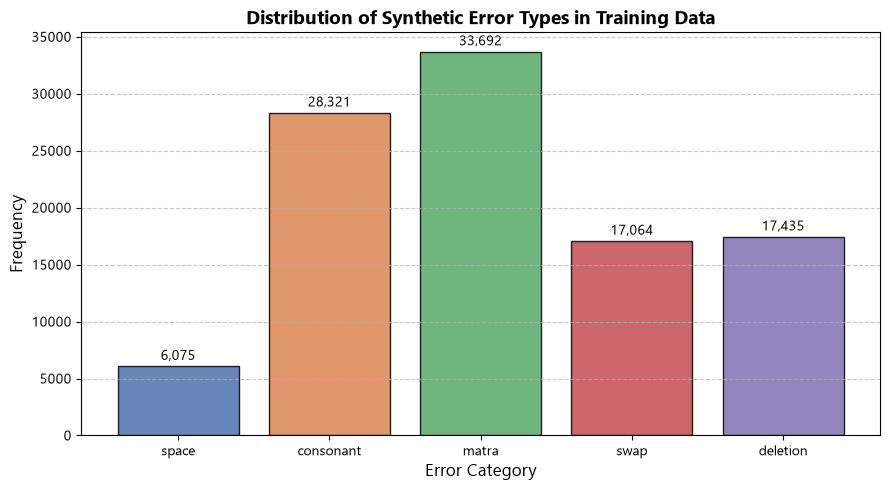


--- Sample Corrupted vs Target Sentence Pairs ---

[Example 1] (Error Type: space)
  ❌ Corrupted Input : ఎర్రనకు రెండు బిరుదులున్నాయి శంభుదాసుడుప్రబంధ పరమేశ్వరుడు
  ✅ Clean Target    : ఎర్రనకు రెండు బిరుదులున్నాయి శంభుదాసుడు ప్రబంధ పరమేశ్వరుడు

[Example 2] (Error Type: consonant,matra,swap)
  ❌ Corrupted Input : కమాంట్ లాంగ్వేజ్, ఇతర ప్రోగ్రామ్ లను ప్రారంభించడం వంటి కంప్యూటర్ యొక్క విధులను నియంత్రించడనాికి ఉపయోగించే భాష
  ✅ Clean Target    : కమాండ్ లాంగ్వేజ్, ఇతర ప్రోగ్రామ్ లను ప్రారంభించడం వంటి కంప్యూటర్ యొక్క విధులను నియంత్రించడానికి ఉపయోగించే భాష

[Example 3] (Error Type: consonant,swap)
  ❌ Corrupted Input : శాశ్వత ప్చచిక ప్రాంతాలు, ఇతర మేత భూమిః 91 హెక్టార్లు
  ✅ Clean Target    : శాశ్వత పచ్చిక ప్రాంతాలు, ఇతర మేత భూమిః 91 హెక్టార్లు

[Example 4] (Error Type: consonant,matra,swap)
  ❌ Corrupted Input : శంఖవరం మండలం నుండి 12 గ్రామాలు, కోటనందూరు మండలం నుండి 31 గ్రామలాు, తుని మంటలం నుండీ ఒక గ్రామాణ్ని విడదీసి ఈకొత్త మండలాన్ని ఏర్పరచారు
  ✅ Clean Target    : శంఖవరం మండలం నుండి 12 గ్రా

In [24]:
# Collect error counts across training set
error_counts = Counter()
for p in train_pairs:
    if p['error_type'] != 'none':
        for et in p['error_type'].split(','):
            error_counts[et.strip()] += 1

print("Error Type Counts in Training Set:")
for et, count in error_counts.most_common():
    print(f"  {et:<12s} : {count:>6,d} ")

# Plot error distribution
plt.figure(figsize=(9, 5))
labels = list(error_counts.keys())
counts = list(error_counts.values())
colors = sns.color_palette("deep", len(labels))

bars = plt.bar(labels, counts, color=colors, edgecolor='black', alpha=0.85)
plt.title("Distribution of Synthetic Error Types in Training Data", fontsize=14, fontweight='bold')
plt.xlabel("Error Category", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 300, f"{yval:,}", ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

# Display 5 clear examples of synthetic noise
print("\n--- Sample Corrupted vs Target Sentence Pairs ---")
sample_corrupt = [p for p in train_pairs if p['input'] != p['target']][:5]
for idx, p in enumerate(sample_corrupt, 1):
    print(f"\n[Example {idx}] (Error Type: {p['error_type']})")
    print(f"  ❌ Corrupted Input : {p['input']}")
    print(f"  ✅ Clean Target    : {p['target']}")
